# Etapa 1 — primeira simulação real com o RuFaS

## Propósito

Aprender o fluxo completo de uma simulação no RuFaS: configurar uma fazenda, gerar a população animal, aplicar uma dieta fixa, executar o modelo e interpretar os resultados produtivos e econômicos. **Este notebook avalia dietas informadas pelo usuário; ele ainda não realiza otimização.**

## O que o notebook faz?

1. Prepara o ambiente e a comunicação com o worker do RuFaS.
2. Configura duração, semente, rebanho, lactação e paridades.
3. Define uma dieta fixa, seus ingredientes, percentuais e preços.
4. Valida as entradas e executa uma simulação real.
5. Apresenta a população inicial efetivamente gerada pela semente.
6. Mostra produção de leite em kg e litros, consumo e evolução do rebanho.
7. Calcula receita, custo alimentar e margem alimentar.
8. Compara a dieta de referência com uma alteração manual da dieta.

## Índice

1. **Introdução e preparação** — carrega bibliotecas, funções do projeto e padrões de formatação.
2. **Configuração da fazenda** — define nome, duração, semente e escopo geral do experimento.
3. **Configuração do rebanho e da lactação** — informa quantidade de vacas, raça, paridades e características do leite.
4. **Configuração da dieta** — monta a dieta fixa com ingredientes, percentuais e preços.
5. **Parâmetros econômicos** — registra preço e unidade do leite, densidade e origem do valor.
6. **Validação das entradas** — verifica faixas, somas e consistência estrutural dos parâmetros.
7. **Execução da simulação** — envia o cenário ao worker, acompanha a fila e carrega o resultado.
8. **População inicial gerada pela semente** — apresenta o rebanho efetivamente sorteado pelo RuFaS.
9. **Leitura dos resultados** — resume produção, população e alimentação ao longo dos dias.
10. **Visualização** — transforma as séries diárias em gráficos de produção e rebanho.
11. **Avaliação econômica** — calcula receita, custo alimentar e margem sobre alimentação.
12. **Comparação de cenários** — compara a dieta de referência com uma alteração manual.

## 1. Introdução e preparação

**O que faz:** carrega as bibliotecas do Python, os componentes desenvolvidos para o projeto e as ferramentas de análise (`pandas`) e visualização (`matplotlib`). Também localiza o volume compartilhado usado pela fila e define o padrão visual das tabelas.

**Resultado desta etapa:** ambiente preparado para configurar, enviar e apresentar uma simulação. Nenhuma fazenda ou animal é criado aqui.

In [1]:
# BLOCO 1 — Ferramentas da biblioteca padrão do Python
# `copy` cria uma cópia independente do cenário de referência. Assim, podemos
# alterar a dieta alternativa sem modificar acidentalmente o cenário original.
import copy
# `os` permite ler variáveis configuradas pelo ambiente Docker.
import os
# `Path` representa caminhos de arquivos e diretórios de forma portátil.
from pathlib import Path

# BLOCO 2 — Bibliotecas para análise e apresentação dos resultados
# `matplotlib` será usado nas células que constroem os gráficos.
import matplotlib.pyplot as plt
# `pandas` organiza configurações e resultados em tabelas (DataFrames).
import pandas as pd

# BLOCO 3 — Componentes desenvolvidos especificamente para este projeto
# As classes *Config representam as entradas da fazenda, do rebanho, do leite,
# da dieta e da economia. As demais funções validam, enviam e acompanham a
# simulação, carregam os resultados e comparam os cenários.
from rufas_project import (
    DietConfig, DietIngredient, EconomicConfig, HerdConfig, MilkConfig,
    ParityFractions, SimulationConfig, calculate_economics, compare_scenarios,
    load_result, submit_simulation, validate_simulation_config, wait_for_simulation,
)

# BLOCO 4 — Conexão entre o notebook e o worker do RuFaS
# O notebook grava as solicitações neste diretório compartilhado. O worker lê
# a solicitação, executa o RuFaS e devolve o estado, os logs e os resultados.
# Se SHARED_ROOT não estiver definido, usamos o caminho padrão do contêiner.
SHARED_ROOT = Path(os.getenv('SHARED_ROOT', '/workspace/shared'))

# BLOCO 5 — Padrão visual reutilizado pelas tabelas do notebook
# Aqui definimos cores, espaçamentos e aparência de títulos, cabeçalhos e células.
TABLE_STYLES = [
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 0')]},
    {'selector': 'th', 'props': [('background-color', '#256a4b'), ('color', 'white'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '7px 12px'), ('border-bottom', '1px solid #e5e7eb')]},
]

# Esta função evita repetir o mesmo código de formatação em todas as células.
# `frame` é a tabela, `caption` é o título e `hide_index` controla a exibição
# da coluna numérica automática criada pelo pandas.
def show_table(frame, caption, hide_index=True):
    styled = frame.style.set_caption(caption).set_table_styles(TABLE_STYLES)
    if hide_index:
        styled = styled.hide(axis='index')
    display(styled)

# BLOCO 6 — Confirmação visual de que o ambiente foi preparado
# A tabela abaixo não cria a fazenda nem executa o RuFaS. Ela apenas mostra
# qual ambiente está sendo usado e onde fica a fila compartilhada.
environment_summary = pd.DataFrame([
    ('Ambiente de execução', 'Jupyter + worker RuFaS'),
    ('Diretório compartilhado', str(SHARED_ROOT)),
    ('Comunicação', 'Fila de arquivos gerada automaticamente'),
], columns=['Item', 'Descrição'])
show_table(environment_summary, 'Ambiente preparado')

Item,Descrição
Ambiente de execução,Jupyter + worker RuFaS
Diretório compartilhado,/workspace/shared
Comunicação,Fila de arquivos gerada automaticamente


## 2. Configuração da fazenda

**O que faz:** cria o cenário principal na memória e define seu nome, quantidade de dias e semente aleatória. O projeto utilizará o modo `animals_only` e o padrão nutricional NASEM quando preparar os arquivos oficiais do RuFaS.

**Resultado desta etapa:** uma configuração geral identificável e reproduzível. Ainda não existem animais nem arquivos de execução; esses valores apenas orientam as etapas seguintes.

In [2]:
# BLOCO 1 — Criação do cenário de simulação na memória
# `SimulationConfig` reúne as configurações que serão enviadas posteriormente
# ao RuFaS. Neste momento ainda não criamos arquivos nem executamos a simulação.
reference = SimulationConfig(
    # Nome usado para identificar o cenário, os arquivos e os resultados.
    name='dieta_referencia',
    # Quantidade de dias que o RuFaS deverá simular.
    simulation_days=30,
    # A semente controla os sorteios da simulação. Usar o mesmo valor permite
    # reproduzir e comparar cenários sob as mesmas condições aleatórias.
    random_seed=42,
)

# BLOCO 2 — Resumo didático da configuração geral
# O projeto prepara o RuFaS no padrão nutricional NASEM e no modo
# `animals_only`, que simula os animais sem ativar lavoura, solo ou esterco.
# A tabela serve apenas para conferência; ela não altera a configuração.
farm_summary = pd.DataFrame([
    ('Nome do cenário', reference.name),
    ('Duração da simulação', f'{reference.simulation_days} dias'),
    ('Semente aleatória', reference.random_seed),
    ('Padrão nutricional', 'NASEM'),
    ('Escopo da simulação', 'Somente animais (animals_only)'),
], columns=['Parâmetro', 'Valor'])

# BLOCO 3 — Apresentação do resumo usando o padrão visual criado anteriormente
show_table(farm_summary, 'Configuração geral da fazenda')

Parâmetro,Valor
Nome do cenário,dieta_referencia
Duração da simulação,30 dias
Semente aleatória,42
Padrão nutricional,NASEM
Escopo da simulação,Somente animais (animals_only)


## 3. Configuração do rebanho e da lactação

**O que faz:** define o número desejado de vacas adultas, raça, fração em lactação e distribuição por número de partos. Também informa gordura e proteína do leite e o peso corporal adulto usado como referência.

**Resultado desta etapa:** um perfil esperado para o rebanho que o RuFaS gerará durante a execução. As proporções orientam a geração, mas a população efetiva depende da semente.

In [3]:
# BLOCO 1 — Parâmetros usados para gerar o rebanho
# Esta configuração informa ao RuFaS quantas vacas queremos e qual perfil
# geral a população deve seguir. Os animais ainda não são criados nesta célula.
reference.herd = HerdConfig(
    # Número de vacas adultas desejado no início do experimento.
    cow_num=20,
    # Fração esperada de vacas produzindo leite; 0.80 corresponde a 80%.
    milking_cow_fraction=0.80,
    breed='HO',  # HO = Holandesa; JE = Jersey
    # Distribuição desejada das vacas conforme o número de partos.
    parity_fractions=ParityFractions(
        parity_1=0.40,
        parity_2=0.25,
        parity_3=0.20,
        parity_4=0.10,
        parity_5=0.05,
    ),
)

# BLOCO 2 — Características do leite e referência de peso adulto
# Estes valores participam dos cálculos produtivos e nutricionais do RuFaS.
reference.milk = MilkConfig(
    fat_percent=4.0,
    protein_percent=3.2,
    mature_body_weight_kg=740.1,
)

# BLOCO 3 — Construção de uma tabela para conferência humana
# A tabela apenas traduz os objetos configurados acima; não altera os valores.
herd_and_milk_summary = pd.DataFrame([
    ('Rebanho', 'Total de vacas', f'{reference.herd.cow_num} animais'),
    ('Rebanho', 'Vacas em lactação (estimativa)', f'{reference.herd.cow_num * reference.herd.milking_cow_fraction:.0f} animais'),
    ('Rebanho', 'Fração em lactação', f'{reference.herd.milking_cow_fraction:.0%}'),
    ('Rebanho', 'Raça', {'HO': 'Holandesa', 'JE': 'Jersey'}[reference.herd.breed]),
    ('Paridade', '1ª lactação', f'{reference.herd.parity_fractions.parity_1:.0%}'),
    ('Paridade', '2ª lactação', f'{reference.herd.parity_fractions.parity_2:.0%}'),
    ('Paridade', '3ª lactação', f'{reference.herd.parity_fractions.parity_3:.0%}'),
    ('Paridade', '4ª lactação', f'{reference.herd.parity_fractions.parity_4:.0%}'),
    ('Paridade', '5ª lactação ou mais', f'{reference.herd.parity_fractions.parity_5:.0%}'),
    ('Leite', 'Gordura', f'{reference.milk.fat_percent:.1f}%'),
    ('Leite', 'Proteína', f'{reference.milk.protein_percent:.1f}%'),
    ('Animal', 'Peso corporal adulto', f'{reference.milk.mature_body_weight_kg:.1f} kg'),
], columns=['Grupo', 'Parâmetro', 'Valor'])

# BLOCO 4 — Formatação e exibição do resumo
# O grupo recebe destaque visual para separar rebanho, paridade, leite e animal.
herd_style = (
    herd_and_milk_summary.style
    .hide(axis='index')
    .set_caption('Resumo do rebanho e dos parâmetros de lactação')
    .set_table_styles(TABLE_STYLES)
    .set_properties(subset=['Grupo'], **{'font-weight': 'bold', 'color': '#256a4b'})
)
display(herd_style)

Grupo,Parâmetro,Valor
Rebanho,Total de vacas,20 animais
Rebanho,Vacas em lactação (estimativa),16 animais
Rebanho,Fração em lactação,80%
Rebanho,Raça,Holandesa
Paridade,1ª lactação,40%
Paridade,2ª lactação,25%
Paridade,3ª lactação,20%
Paridade,4ª lactação,10%
Paridade,5ª lactação ou mais,5%
Leite,Gordura,4.0%


## 4. Configuração da dieta

**O que faz:** define diretamente os ingredientes oferecidos às vacas em lactação, seus IDs no RuFaS, participações percentuais e custos por kg de matéria seca. Os valores iniciais foram baseados em `example_Midwest_feed.json`.

**Resultado desta etapa:** uma dieta fixa totalizando 100% de matéria seca, pronta para ser avaliada. O RuFaS ainda não escolhe os percentuais nem procura o menor custo.

In [4]:
# BLOCO 1 — Definição da dieta fornecida às vacas em lactação
# `fixed` indica que os percentuais são definidos por nós. Nesta Etapa 1,
# o RuFaS avalia a dieta informada, mas não escolhe as quantidades.
reference.diet = DietConfig(
    mode='fixed',  # use 'rufas_min_cost' para o otimizador interno SLSQP
    # Intervalo entre reformulações; como a dieta é fixa, mantemos 30 dias.
    formulation_interval_days=30,
    # Cada ingrediente contém: ID RuFaS, percentual, custo por kg de MS e nome.
    ingredients=[
        DietIngredient(23, 0.74, 0.10, 'Blood meal, low dRUP'),
        DietIngredient(44, 15.31, 0.50, 'Corn grain dry, medium grind'),
        DietIngredient(50, 37.45, 0.01, 'Corn silage, immature'),
        DietIngredient(104, 0.37, 0.01, 'Grass/legume mix, legume silage'),
        DietIngredient(110, 17.65, 0.01, 'Legume silage, mid-maturity'),
        DietIngredient(301, 3.27, 1.00, 'Farm ES Mineral Mix'),
        DietIngredient(302, 25.21, 0.10, 'Farm ES Midwest BP Blend'),
    ],
)

# BLOCO 2 — Tradução dos nomes dos ingredientes
# O ID continua sendo a chave técnica usada pelo RuFaS; o texto em português
# existe somente para tornar a leitura do notebook mais clara.
ingredient_names_pt = {
    23: 'Farinha de sangue, baixo teor de proteína digestível não degradável no rúmen (dRUP)',
    44: 'Grão de milho seco, moagem média',
    50: 'Silagem de milho imatura',
    104: 'Mistura de gramínea e leguminosa ensilada',
    110: 'Silagem de leguminosa em maturação intermediária',
    301: 'Mistura mineral da fazenda (ES)',
    302: 'Mistura proteica de subprodutos do Meio-Oeste (BP)',
}

# BLOCO 3 — Conversão da lista de ingredientes em tabela
# A compreensão de lista percorre cada ingrediente e cria uma linha legível.
diet_table = pd.DataFrame([
    {
        'ID no RuFaS': item.feed_type,
        'Ingrediente em português': ingredient_names_pt[item.feed_type],
        'Nome original no RuFaS': item.name,
        'Participação na dieta': f'{item.ration_percentage:.2f}%',
        'Custo (USD/kg de MS)': f'{item.purchased_feed_cost_usd_per_kg_dm:.2f}',
    }
    for item in reference.diet.ingredients
])

# BLOCO 4 — Exibição e verificação da soma da dieta
# Em uma dieta fixa, os percentuais precisam totalizar exatamente 100%.
show_table(diet_table, 'Ingredientes da dieta de referência')
diet_total = sum(item.ration_percentage for item in reference.diet.ingredients)
print(f'Soma da dieta: {diet_total:.2f}%')

ID no RuFaS,Ingrediente em português,Nome original no RuFaS,Participação na dieta,Custo (USD/kg de MS)
23,"Farinha de sangue, baixo teor de proteína digestível não degradável no rúmen (dRUP)","Blood meal, low dRUP",0.74%,0.10
44,"Grão de milho seco, moagem média","Corn grain dry, medium grind",15.31%,0.50
50,Silagem de milho imatura,"Corn silage, immature",37.45%,0.01
104,Mistura de gramínea e leguminosa ensilada,"Grass/legume mix, legume silage",0.37%,0.01
110,Silagem de leguminosa em maturação intermediária,"Legume silage, mid-maturity",17.65%,0.01
301,Mistura mineral da fazenda (ES),Farm ES Mineral Mix,3.27%,1.00
302,Mistura proteica de subprodutos do Meio-Oeste (BP),Farm ES Midwest BP Blend,25.21%,0.10


Soma da dieta: 100.00%


## 5. Parâmetros econômicos

**O que faz:** registra o preço do leite, sua unidade (`por kg` ou `por litro`), a densidade usada na conversão e a origem do valor. A moeda permanece em USD, assim como os custos dos alimentos.

**Resultado desta etapa:** premissas documentadas para converter a produção do RuFaS em receita. Quando o preço é informado por litro, o projeto o converte para USD/kg antes do cálculo econômico.

In [5]:
# BLOCO 1 — Premissas econômicas externas ao RuFaS
# O preço do leite não é sorteado nem calculado pela simulação. Ele é uma
# hipótese informada pelo usuário para transformar a produção em receita.
reference.economics = EconomicConfig(
    # Valor comercial informado pelo usuário.
    milk_price=0.45,
    # Opções: `per_kg` para preço por kg ou `per_liter` para preço por litro.
    milk_price_unit='per_liter',
    # Usada somente quando é necessário converter litros para kg.
    milk_density_kg_per_liter=1.03,
    milk_price_source=(
        'Hipótese didática; confirmar fonte, região e data antes da análise final'
    ),
    currency='USD',
)

# BLOCO 2 — Organização das premissas em uma tabela de conferência
unit_labels = {'per_kg': 'por kg', 'per_liter': 'por litro'}
input_unit_symbol = 'kg' if reference.economics.milk_price_unit == 'per_kg' else 'L'
economic_inputs = pd.DataFrame([
    ('Preço informado', f'{reference.economics.milk_price:.2f} {reference.economics.currency}/{input_unit_symbol}'),
    ('Unidade selecionada', unit_labels[reference.economics.milk_price_unit]),
    ('Moeda', reference.economics.currency),
    ('Densidade adotada', f'{reference.economics.milk_density_kg_per_liter:.3f} kg/L'),
    ('Preço normalizado para o RuFaS', f'{reference.economics.milk_price_per_kg:.4f} {reference.economics.currency}/kg'),
    ('Origem do preço', reference.economics.milk_price_source),
], columns=['Parâmetro econômico', 'Valor'])

# BLOCO 3 — Apresentação das premissas que serão usadas após a simulação
show_table(economic_inputs, 'Premissas econômicas')

Parâmetro econômico,Valor
Preço informado,0.45 USD/L
Unidade selecionada,por litro
Moeda,USD
Densidade adotada,1.030 kg/L
Preço normalizado para o RuFaS,0.4369 USD/kg
Origem do preço,"Hipótese didática; confirmar fonte, região e data antes da análise final"


## 6. Validação das entradas

**O que faz:** verifica se os valores estão dentro das faixas aceitas, se as paridades e a dieta somam 100%, se não existem percentuais ou custos negativos e se a unidade do preço é válida.

**Resultado desta etapa:** confirmação de que o cenário possui estrutura suficiente para ser executado. Essa validação não comprova atendimento nutricional nem dieta ótima.

In [6]:
# BLOCO 1 — Validação automática antes da execução
# A função interrompe a célula com uma mensagem de erro se encontrar valores
# inválidos, como dieta diferente de 100% ou paridades inconsistentes.
validate_simulation_config(reference)

# BLOCO 2 — Resumo das verificações importantes para o experimento
validation_summary = pd.DataFrame([
    ('Configuração geral', 'Válida'),
    ('Soma da dieta', f'{diet_total:.2f}%'),
    ('Soma das paridades', '100%'),
    ('Pronto para simular', 'Sim'),
], columns=['Verificação', 'Resultado'])

# BLOCO 3 — Confirmação visual de que a configuração pode ser enviada
show_table(validation_summary, 'Validação das entradas concluída')

Verificação,Resultado
Configuração geral,Válida
Soma da dieta,100.00%
Soma das paridades,100%
Pronto para simular,Sim


## 7. Execução da simulação

**O que faz:** grava o cenário na fila compartilhada e gera um UUID para acompanhar a execução. O `rufas-worker` prepara os arquivos de entrada, gera a população, executa o `main.py` do RuFaS e processa as saídas.

**Resultado desta etapa:** uma simulação concluída com estado, logs e resultados associados ao identificador da execução. O notebook aguarda até 1.800 segundos antes de indicar tempo excedido.

In [7]:
# BLOCO 1 — Envio do cenário para a fila compartilhada
# A função grava a configuração e devolve um UUID que identifica esta execução.
reference_job = submit_simulation(reference, SHARED_ROOT)

# BLOCO 2 — Espera pelo término do worker
# O notebook consulta o estado periodicamente, por no máximo 1.800 segundos.
reference_status = wait_for_simulation(reference_job, SHARED_ROOT, timeout_seconds=1800)

# BLOCO 3 — Carregamento do resultado processado
# Este objeto contém métricas, séries diárias e a população inicial gerada.
reference_result = load_result(reference_job, SHARED_ROOT)

# BLOCO 4 — Resumo da execução concluída
execution_summary = pd.DataFrame([
    ('Identificador da execução', reference_job),
    ('Cenário', reference_status['scenario']),
    ('Situação final', 'Concluída com sucesso'),
    ('Mensagem', reference_status['message']),
], columns=['Item', 'Valor'])
show_table(execution_summary, 'Execução do RuFaS')

Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados


Item,Valor
Identificador da execução,4ef4ca59-bc61-4c8d-bd57-95f72bcb0e64
Cenário,dieta_referencia
Situação final,Concluída com sucesso
Mensagem,Simulação concluída e resultados processados


## 8. População inicial gerada pela semente

**O que faz:** lê o resumo da população criada pelo próprio RuFaS antes do primeiro dia simulado. A semente não armazena animais; ela controla os sorteios de idade, peso, estágio, lactação, gestação e paridade dentro das regras configuradas.

**Resultado desta etapa:** quantidades efetivas de bezerras, novilhas e vacas, além de médias de idade, peso, lactação, gestação e partos. Mantendo semente, entradas e versão do RuFaS, a população pode ser reproduzida.

> O relatório padrão fornece estatísticas agregadas, e não uma ficha individual de cada animal.

In [8]:
# BLOCO 1 — Recuperação da população inicial gerada
# O worker extrai estas informações do resumo oficial produzido pelo RuFaS.
# São dados agregados do rebanho, não registros individuais de cada animal.
initial_population = reference_result['initial_population']

# BLOCO 2 — Função auxiliar para apresentar valores e unidades
# Quando um indicador não estiver no relatório, mostramos uma descrição em vez
# de deixar `None` ou `NaN` aparecer na tabela.
def format_initial_value(value, decimals=0, unit=''):
    if value is None:
        return 'Não informado pelo RuFaS'
    suffix = f' {unit}' if unit else ''
    formatted = f'{value:,.{decimals}f}'
    formatted_pt_br = formatted.replace(',', 'TEMP').replace('.', ',').replace('TEMP', '.')
    return f'{formatted_pt_br}{suffix}'

# BLOCO 3 — Tradução do código técnico da raça
breed_names = {'HO': 'Holandesa', 'Holstein': 'Holandesa', 'JE': 'Jersey', 'Jersey': 'Jersey'}
breed_raw = initial_population['breed']
breed_value = str(breed_raw).strip().strip('{}[]()').replace(chr(39), '').replace(chr(34), '').strip() if breed_raw else None
breed_description = breed_names.get(breed_value, breed_value or 'Não informada')
breed_display = (
    f'{breed_description} ({breed_value})'
    if breed_value and breed_description != breed_value
    else breed_description
)

# BLOCO 4 — Cálculo do total de animais por estágio de vida
# Somamos bezerras, três grupos de novilhas e vacas. Valores ausentes não
# entram na soma; se nenhum grupo existir, o total permanece não informado.
stage_keys = [
    'number_of_calves', 'number_of_heifer_is', 'number_of_heifer_iis',
    'number_of_heifer_iiis', 'number_of_cows',
]
stage_values = [initial_population[key] for key in stage_keys]
reported_stage_values = [value for value in stage_values if value is not None]
total_animals = sum(reported_stage_values) if reported_stage_values else None

# BLOCO 5 — Resumo das características efetivamente sorteadas
# Estes são os valores resultantes da semente, e não apenas as proporções
# desejadas que foram informadas na configuração do rebanho.
initial_summary = pd.DataFrame([
    ('Semente aleatória utilizada', str(initial_population['random_seed']) if initial_population['random_seed'] is not None else 'Não informada'),
    ('Raça', breed_display),
    ('Total de animais', format_initial_value(total_animals, unit='animais')),
    ('Bezerras', format_initial_value(initial_population['number_of_calves'], unit='animais')),
    ('Novilhas I', format_initial_value(initial_population['number_of_heifer_is'], unit='animais')),
    ('Novilhas II', format_initial_value(initial_population['number_of_heifer_iis'], unit='animais')),
    ('Novilhas III', format_initial_value(initial_population['number_of_heifer_iiis'], unit='animais')),
    ('Vacas', format_initial_value(initial_population['number_of_cows'], unit='animais')),
    ('Vacas em lactação', format_initial_value(initial_population['number_of_lactating_cows'], unit='animais')),
    ('Vacas secas', format_initial_value(initial_population['number_of_dry_cows'], unit='animais')),
    ('Idade média das vacas', format_initial_value(initial_population['average_cow_age_days'], 1, 'dias')),
    ('Peso corporal médio das vacas', format_initial_value(initial_population['average_cow_body_weight_kg'], 1, 'kg')),
    ('Dias em gestação (média)', format_initial_value(initial_population['average_cow_days_in_pregnancy'], 1, 'dias')),
    ('Dias em lactação (média)', format_initial_value(initial_population['average_cow_days_in_milk'], 1, 'dias')),
    ('Número médio de partos', format_initial_value(initial_population['average_cow_parity'], 2)),
], columns=['Característica inicial', 'Valor gerado'])
show_table(initial_summary, 'População inicial efetivamente gerada pelo RuFaS')

# BLOCO 6 — Distribuição das vacas pelo número de partos
# Traduzimos as chaves do relatório e removemos somente grupos não informados.
parity_labels = {
    '1': '1º parto', '2': '2º parto', '3': '3º parto',
    '4': '4º parto', '5': '5º parto', '6_or_more': '6 ou mais partos',
}
parity_table = pd.DataFrame([
    (parity_labels[parity], int(quantity))
    for parity, quantity in initial_population['parity_distribution'].items()
    if quantity is not None
], columns=['Grupo de paridade', 'Quantidade de vacas'])
show_table(parity_table, 'Distribuição inicial das vacas por número de partos')

Característica inicial,Valor gerado
Semente aleatória utilizada,42
Raça,Holandesa (Holstein)
Total de animais,114 animais
Bezerras,8 animais
Novilhas I,44 animais
Novilhas II,38 animais
Novilhas III,5 animais
Vacas,19 animais
Vacas em lactação,15 animais
Vacas secas,4 animais


Grupo de paridade,Quantidade de vacas
1º parto,8
2º parto,5
3º parto,4
4º parto,2
5º parto,0
6 ou mais partos,0


## 9. Leitura dos resultados

**O que faz:** transforma as saídas processadas em indicadores consolidados e séries diárias. Apresenta população, produção total, média e pico de leite em kg e litros, dias em lactação e matéria seca ofertada.

**Resultado desta etapa:** tabelas legíveis com os principais resultados e uma prévia dos cinco primeiros dias, preservando a série completa para as análises seguintes.

In [9]:
# BLOCO 1 — Separação das séries diárias e das métricas consolidadas
# `series` possui uma linha por dia; `metrics` contém totais, médias e valores
# iniciais ou finais já calculados pelo módulo de processamento. A densidade
# permite apresentar também o volume equivalente: litros = kg ÷ kg/L.
reference_series = pd.DataFrame(reference_result['series'])
metrics = reference_result['metrics']
milk_density = reference.economics.milk_density_kg_per_liter

# BLOCO 2 — Tabela com os principais indicadores da execução
metrics_summary = pd.DataFrame([
    ('Vacas em lactação no início', f"{metrics['initial_lactating_cows']:.0f} animais"),
    ('Vacas em lactação ao final', f"{metrics['final_lactating_cows']:.0f} animais"),
    ('Vacas secas ao final', f"{metrics['final_dry_cows']:.0f} animais"),
    ('Total de vacas ao final', f"{metrics['final_total_cows']:.0f} animais"),
    ('Produção total de leite', f"{metrics['total_milk_kg']:,.2f} kg"),
    ('Produção total de leite (volume equivalente)', f"{metrics['total_milk_kg'] / milk_density:,.2f} litros"),
    ('Produção média diária', f"{metrics['average_daily_milk_kg']:,.2f} kg/dia"),
    ('Produção média diária (volume equivalente)', f"{metrics['average_daily_milk_kg'] / milk_density:,.2f} L/dia"),
    ('Pico de produção diária', f"{metrics['peak_daily_milk_kg']:,.2f} kg/dia"),
    ('Pico de produção diária (volume equivalente)', f"{metrics['peak_daily_milk_kg'] / milk_density:,.2f} L/dia"),
    ('Média de dias em lactação ao final', f"{metrics['final_avg_days_in_milk']:.1f} dias"),
], columns=['Indicador', 'Resultado'])
show_table(metrics_summary, 'Principais resultados produzidos pelo RuFaS')

# BLOCO 3 — Preparação de uma amostra da evolução diária
# A dieta diária vem separada por ingrediente. A função `lambda` soma esses
# valores para obter o total de matéria seca ofertada às vacas em lactação.
daily_preview = reference_series.assign(
    milk_liters=reference_series['milk_kg'] / milk_density,
    total_feed_kg_dm=reference_series['lactating_feed_kg_dm'].map(
        lambda feeds: sum(feeds.values())
    )
)[[
    'day', 'lactating_cows', 'dry_cows', 'total_cows',
    'milk_kg', 'milk_liters', 'avg_days_in_milk', 'total_feed_kg_dm',
]].rename(columns={
    'day': 'Dia',
    'lactating_cows': 'Vacas em lactação',
    'dry_cows': 'Vacas secas',
    'total_cows': 'Total de vacas',
    'milk_kg': 'Leite (kg/dia)',
    'milk_liters': 'Leite equivalente (L/dia)',
    'avg_days_in_milk': 'Dias em lactação (média)',
    'total_feed_kg_dm': 'Dieta ofertada (kg MS/dia)',
})

# BLOCO 4 — Formatação e apresentação dos cinco primeiros dias
# `head()` limita a prévia sem apagar os outros dias de `reference_series`.
daily_style = (
    daily_preview.head().style
    .hide(axis='index')
    .set_caption('Primeiros cinco dias da simulação')
    .set_table_styles(TABLE_STYLES)
    .format({
        'Vacas em lactação': '{:.0f}', 'Vacas secas': '{:.0f}', 'Total de vacas': '{:.0f}',
        'Leite (kg/dia)': '{:,.2f}', 'Leite equivalente (L/dia)': '{:,.2f}',
        'Dias em lactação (média)': '{:.1f}',
        'Dieta ofertada (kg MS/dia)': '{:,.2f}',
    })
)
display(daily_style)

Indicador,Resultado
Vacas em lactação no início,15 animais
Vacas em lactação ao final,20 animais
Vacas secas ao final,4 animais
Total de vacas ao final,24 animais
Produção total de leite,"22,442.17 kg"
Produção total de leite (volume equivalente),"21,788.51 litros"
Produção média diária,748.07 kg/dia
Produção média diária (volume equivalente),726.28 L/dia
Pico de produção diária,829.75 kg/dia
Pico de produção diária (volume equivalente),805.58 L/dia


Dia,Vacas em lactação,Vacas secas,Total de vacas,Leite (kg/dia),Leite equivalente (L/dia),Dias em lactação (média),Dieta ofertada (kg MS/dia)
1,15,4,19,624.90,606.69,121.3,415.13
2,16,4,20,643.38,624.64,114.7,442.80
3,16,4,20,651.71,632.73,115.7,442.80
4,17,4,21,669.89,650.37,109.9,470.48
5,17,4,21,675.21,655.55,110.9,470.48


## 10. Visualização

**O que faz:** utiliza as séries diárias para construir gráficos da produção de leite e das quantidades de vacas em lactação e secas ao longo do tempo.

**Resultado desta etapa:** uma leitura visual de tendências, variações e mudanças no rebanho que seriam menos evidentes apenas nas tabelas.

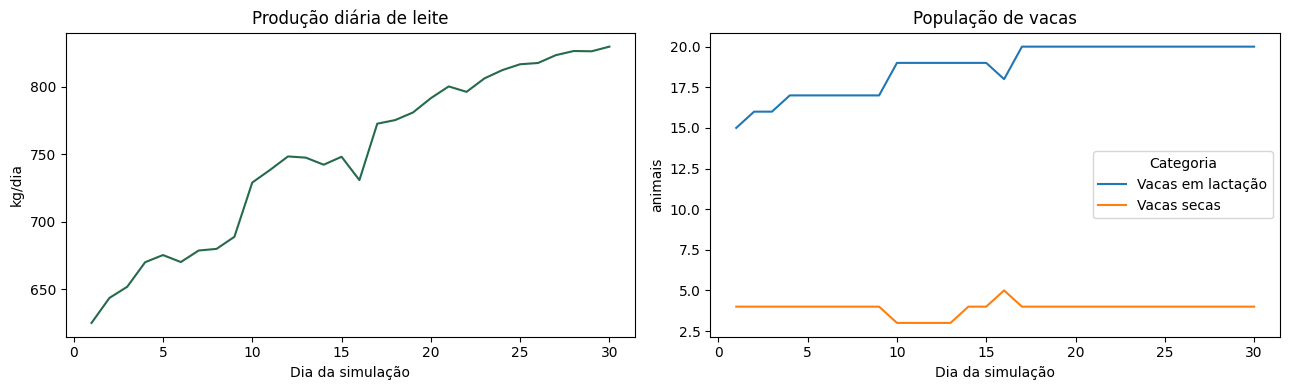

In [10]:
# BLOCO 1 — Criação de uma figura com dois espaços para gráficos
# `fig` representa a figura completa e `axes` contém os dois painéis.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# BLOCO 2 — Evolução da produção de leite e da população de vacas
# Ambos usam o dia da simulação no eixo horizontal para facilitar a comparação.
reference_series.plot(x='day', y='milk_kg', ax=axes[0], color='#256a4b', title='Produção diária de leite', legend=False)
reference_series.plot(x='day', y=['lactating_cows', 'dry_cows'], ax=axes[1], title='População de vacas')

# BLOCO 3 — Tradução dos eixos e da legenda
axes[0].set_xlabel('Dia da simulação')
axes[0].set_ylabel('kg/dia')
axes[1].set_xlabel('Dia da simulação')
axes[1].set_ylabel('animais')
axes[1].legend(['Vacas em lactação', 'Vacas secas'], title='Categoria')

# BLOCO 4 — Ajuste automático dos espaçamentos da figura
plt.tight_layout()

## 11. Avaliação econômica

**O que faz:** combina produção e consumo simulados pelo RuFaS com os preços informados no notebook. Calcula receita do leite, custo da alimentação das vacas em lactação e margem sobre o custo alimentar.

**Resultado desta etapa:** uma avaliação econômica parcial do cenário. A margem não representa lucro líquido, pois não inclui mão de obra, energia, sanidade, instalações e outros custos da fazenda.

In [11]:
# BLOCO 1 — Cálculo econômico a partir da produção e do consumo simulados
# A função combina as saídas reais do RuFaS com preços definidos no cenário.
reference_economics = calculate_economics(reference_result, reference)

# BLOCO 2 — Organização dos resultados econômicos
# A margem apresentada é receita do leite menos custo alimentar das vacas em
# lactação; ela não representa o lucro total da fazenda.
economic_summary = pd.DataFrame([
    ('Origem dos cálculos', reference_economics['source']),
    ('Preço informado do leite', f"{reference_economics['milk_price_input']:.2f} {reference_economics['currency']}/{'L' if reference_economics['milk_price_input_unit'] == 'per_liter' else 'kg'}"),
    ('Preço convertido para o cálculo', f"{reference_economics['milk_price_per_kg']:.4f} {reference_economics['currency']}/kg"),
    ('Produção total', f"{reference_economics['total_milk_kg']:,.2f} kg"),
    ('Volume equivalente', f"{reference_economics['total_milk_liters_equivalent']:,.2f} litros"),
    ('Receita total do leite', f"{reference_economics['total_milk_revenue']:,.2f} {reference_economics['currency']}"),
    ('Custo da alimentação das vacas em lactação', f"{reference_economics['total_lactating_feed_cost']:,.2f} {reference_economics['currency']}"),
    ('Margem sobre o custo alimentar', f"{reference_economics['margin_over_lactating_feed_cost']:,.2f} {reference_economics['currency']}"),
], columns=['Indicador econômico', 'Resultado'])

# BLOCO 3 — Exibição da avaliação econômica do cenário de referência
show_table(economic_summary, 'Avaliação econômica do cenário de referência')

Indicador econômico,Resultado
Origem dos cálculos,"Calculado pelo projeto, não pelo RuFaS"
Preço informado do leite,0.45 USD/L
Preço convertido para o cálculo,0.4369 USD/kg
Produção total,"22,442.17 kg"
Volume equivalente,"21,788.51 litros"
Receita total do leite,"9,804.83 USD"
Custo da alimentação das vacas em lactação,"1,950.97 USD"
Margem sobre o custo alimentar,"7,853.86 USD"


## 12. Comparação de cenários

**O que faz:** cria uma cópia independente do cenário de referência, retira dois pontos percentuais da silagem de milho e os adiciona ao milho moído. A alternativa usa a mesma semente para reduzir diferenças aleatórias entre as execuções.

**Resultado desta etapa:** uma comparação lado a lado de produção, custo, receita e margem. A alteração é manual e didática; não representa uma solução otimizada nem uma recomendação geral.

A Etapa 2 implementa a otimização. Nela, o RuFaS/NASEM roda primeiro para produzir uma dieta de referência; o projeto calcula os fornecimentos de TDN, proteína bruta, cálcio, fósforo e NDF dessa dieta e usa esses cinco valores como pisos do nosso modelo linear. O Notebook 1 não calcula nem transfere essas restrições.

Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados


,Leite total (kg),Média de leite (kg/dia),Custo alimentar (USD),Receita do leite (USD),Margem alimentar (USD)
Cenário,,,,,
Referência,"22,442.17",748.07,"1,950.97","9,804.83","7,853.86"
Alternativa,"22,442.17",748.07,"2,137.07","9,804.83","7,667.76"


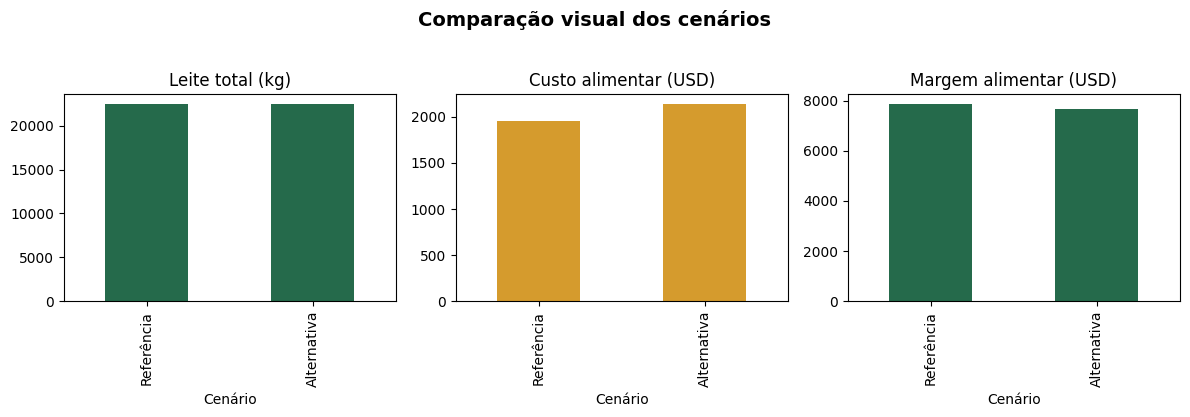

In [12]:
# BLOCO 1 — Criação de um cenário independente para comparação
# `deepcopy` copia também os objetos internos. Assim, alterar a alternativa
# não modifica a dieta nem os resultados do cenário de referência.
alternative = copy.deepcopy(reference)
alternative.name = 'dieta_alternativa'

# BLOCO 2 — Alteração controlada da composição da dieta
# O dicionário permite localizar ingredientes pelo ID. Retiramos dois pontos
# percentuais da silagem de milho e os transferimos para o milho moído,
# mantendo a soma total da dieta em 100%. Isso é um cenário, não uma otimização.
ingredient_by_id = {item.feed_type: item for item in alternative.diet.ingredients}
# ingredient_by_id[50].ration_percentage -= 2.0  # silagem de milho
# ingredient_by_id[44].ration_percentage += 2.0  # milho moído

# segundo cenário de dieta em 100%
ingredient_by_id[50].ration_percentage -= 5.0 # silagem de milho
ingredient_by_id[44].ration_percentage += 3.0 # milho moído
ingredient_by_id[110].ration_percentage += 2.0 # Silagem de leguminosa em maturação intermediária

# BLOCO 3 — Validação, envio e leitura da simulação alternativa
# Como a semente foi copiada, os dois cenários usam a mesma sequência de
# sorteios, ajudando a isolar o efeito da alteração da dieta.
validate_simulation_config(alternative)
alternative_job = submit_simulation(alternative, SHARED_ROOT)
wait_for_simulation(alternative_job, SHARED_ROOT, timeout_seconds=1800)
alternative_result = load_result(alternative_job, SHARED_ROOT)

# BLOCO 4 — Cálculo econômico e comparação dos dois cenários
alternative_economics = calculate_economics(alternative_result, alternative)
comparison = compare_scenarios({
    'Referência': (reference_result, reference_economics),
    'Alternativa': (alternative_result, alternative_economics),
})

# BLOCO 5 — Tradução dos nomes técnicos das colunas
comparison_display = comparison.rename(columns={
    'milk_kg': 'Leite total (kg)',
    'average_daily_milk_kg': 'Média de leite (kg/dia)',
    'feed_cost': 'Custo alimentar (USD)',
    'milk_revenue': 'Receita do leite (USD)',
    'margin_over_feed_cost': 'Margem alimentar (USD)',
}).rename_axis('Cenário')

# BLOCO 6 — Formatação e exibição da tabela comparativa
comparison_style = (
    comparison_display.style
    .set_caption('Comparação dos cenários simulados')
    .set_table_styles(TABLE_STYLES)
    .format('{:,.2f}')
)
display(comparison_style)

# BLOCO 7 — Comparação visual de produção, custo e margem
# Cada indicador recebe um painel próprio porque possui escala diferente.
comparison_display[[
    'Leite total (kg)', 'Custo alimentar (USD)', 'Margem alimentar (USD)'
]].plot.bar(figsize=(12, 4), subplots=True, layout=(1, 3), legend=False, color=['#256a4b', '#d59b2d'])
plt.suptitle('Comparação visual dos cenários', y=1.03, fontsize=14, fontweight='bold')
plt.xlabel('Cenário')
plt.tight_layout()